# Sarva Mitra: crop risk model, full data-science lifecycle

**Question:** given the last 7 days of field records and today's sensed reading, how risky is the next day for the crop, on a 0 to 100 index, and what is the risk label?

**Data:** `dataset.csv`, 15 columns, 28 points, 2000 to 2026. Target `risk_pct`.

**Central rule:** `risk_pct` is a formula of same-day weather and soil. A model that sees same-day weather reproduces the formula. So the model uses **previous-day** values only, which is also what an early-warning system can use.

| Stage | Section |
|---|---|
| 1. Problem and success criteria | this section |
| 2. Data understanding | 3 |
| 3. Data quality | 4 |
| 4. Exploratory analysis | 5 |
| 5. Leakage check | 6 |
| 6. Feature engineering | 7 |
| 7. Split and baseline | 8 |
| 8. Modelling | 9 |
| 9. Diagnosis (overfitting and underfitting) | 10 |
| 10. Tuning | 11 |
| 11. Selection | 12 |
| 12. Evaluation (score and risk label) | 13 |
| 13. Deployment artefacts and API check | 14 |
| 14. Monitoring and retraining | 15 |

**Success criteria (set before modelling):** beat the climatology baseline by a clear margin on the test years; the risk label should match the true label on most days; the gap between training and validation error stays small.


## 2. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import xgboost as xgb

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
# The API and the notebook share this code, so features cannot drift between training and serving
from backend import FEATURES, DYNAMIC, STATIC, RECORD_STATIC, add_features, risk_label

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
DATA = HERE / "dataset.csv"
MODEL_DIR = HERE / "models"
MODEL_DIR.mkdir(exist_ok=True)
TARGET = "risk_pct"
TRAIN_END, VAL_END = 2019, 2022        # train 2000-2019 | validation 2020-2022 | test 2023-2025
RANDOM_STATE = 42
metrics_log = {}

## 3. Data understanding
What is in the file, what each column means, and whether it is complete.

In [2]:
raw = pd.read_csv(DATA, parse_dates=["date"])
print("rows, columns:", raw.shape)
print("points:", raw.groupby(["lat", "lon"]).ngroups)
print("dates:", raw.date.min().date(), "to", raw.date.max().date())
print("column types:"); print(raw.dtypes.to_string())
display(raw.describe().T.round(2))

rows, columns: (274876, 15)
points: 28
dates: 2000-01-01 to 2026-11-16
column types:
date                 datetime64[us]
lat                         float64
lon                         float64
soil_moisture_pct           float64
air_temperature_c           float64
humidity_pct                float64
sunlight_wm2                float64
rainfall_mm                 float64
soil_ph                     float64
organic_carbon              float64
clay_pct                    float64
sand_pct                    float64
silt_pct                    float64
elevation_m                 float64
risk_pct                    float64


,count,mean,min,25%,50%,75%,max,std
date,274876,2013-06-09 00:00:00,2000-01-01 00:00:00,2006-09-20 00:00:00,2013-06-09 00:00:00,2020-02-27 00:00:00,2026-11-16 00:00:00,NaN
lat,274876.0,23.002143,8.52,20.9375,23.78,26.865,31.1,5.58293
lon,274876.0,83.017857,72.65,77.35,80.735,89.2775,94.11,6.843834
soil_moisture_pct,274876.0,57.30911,6.0,38.0,59.0,78.0,100.0,24.391834
air_temperature_c,274876.0,23.863096,-7.02,19.9,25.11,28.2,42.01,6.766282
humidity_pct,274876.0,64.907424,4.19,49.91,70.45,83.12,100.0,21.739286
sunlight_wm2,274876.0,201.934623,10.763889,164.00463,203.587963,244.560185,368.634259,58.802037
rainfall_mm,274876.0,3.867988,0.0,0.0,0.1,3.4,386.24,9.369881
soil_ph,274876.0,6.4,5.1,5.775,6.25,7.05,7.9,0.785586
organic_carbon,274876.0,16.714286,3.5,7.875,13.25,21.2,54.6,12.493584


Soil and elevation are fixed per point. Each should have exactly one value per point, and should differ between points.

In [3]:
static_cols = ["soil_ph", "organic_carbon", "clay_pct", "sand_pct", "silt_pct", "elevation_m"]
per_point = raw.groupby(["lat", "lon"])[static_cols].nunique()
print("max distinct values within one point (should be 1):", int(per_point.max().max()))
print("distinct values across points:"); print(raw.groupby(["lat", "lon"])[static_cols].first().nunique().to_string())

max distinct values within one point (should be 1): 1
distinct values across points:


soil_ph           18
organic_carbon    27
clay_pct          19
sand_pct          24
silt_pct          18
elevation_m       26


## 4. Data quality
Rules are applied, not guessed. Each one is counted and reported.

In [4]:
q = {}
q["rows_in"] = len(raw)
q["duplicate (date, lat, lon)"] = int(raw.duplicated(["date", "lat", "lon"]).sum())
q["missing values"] = raw.isna().sum()[lambda s: s > 0].to_dict()
q["humidity outside 0-100"] = int(((raw.humidity_pct < 0) | (raw.humidity_pct > 100)).sum())
q["soil moisture outside 0-100"] = int(((raw.soil_moisture_pct < 0) | (raw.soil_moisture_pct > 100)).sum())
q["negative rainfall"] = int((raw.rainfall_mm < 0).sum())
q["air temperature below 5 C (kept; winter in the Himalayan states)"] = int((raw.air_temperature_c < 5).sum())
q["risk outside 0-100"] = int(((raw[TARGET] < 0) | (raw[TARGET] > 100)).sum())
for k, v in q.items():
    print(f"{k}: {v}")
metrics_log["data_quality"] = {k: (v if not isinstance(v, dict) else {kk: int(vv) for kk, vv in v.items()}) for k, v in q.items()}

rows_in: 274876
duplicate (date, lat, lon): 0
missing values: {}
humidity outside 0-100: 0
soil moisture outside 0-100: 0
negative rainfall: 0
air temperature below 5 C (kept; winter in the Himalayan states): 3468
risk outside 0-100: 0


## 5. Exploratory analysis

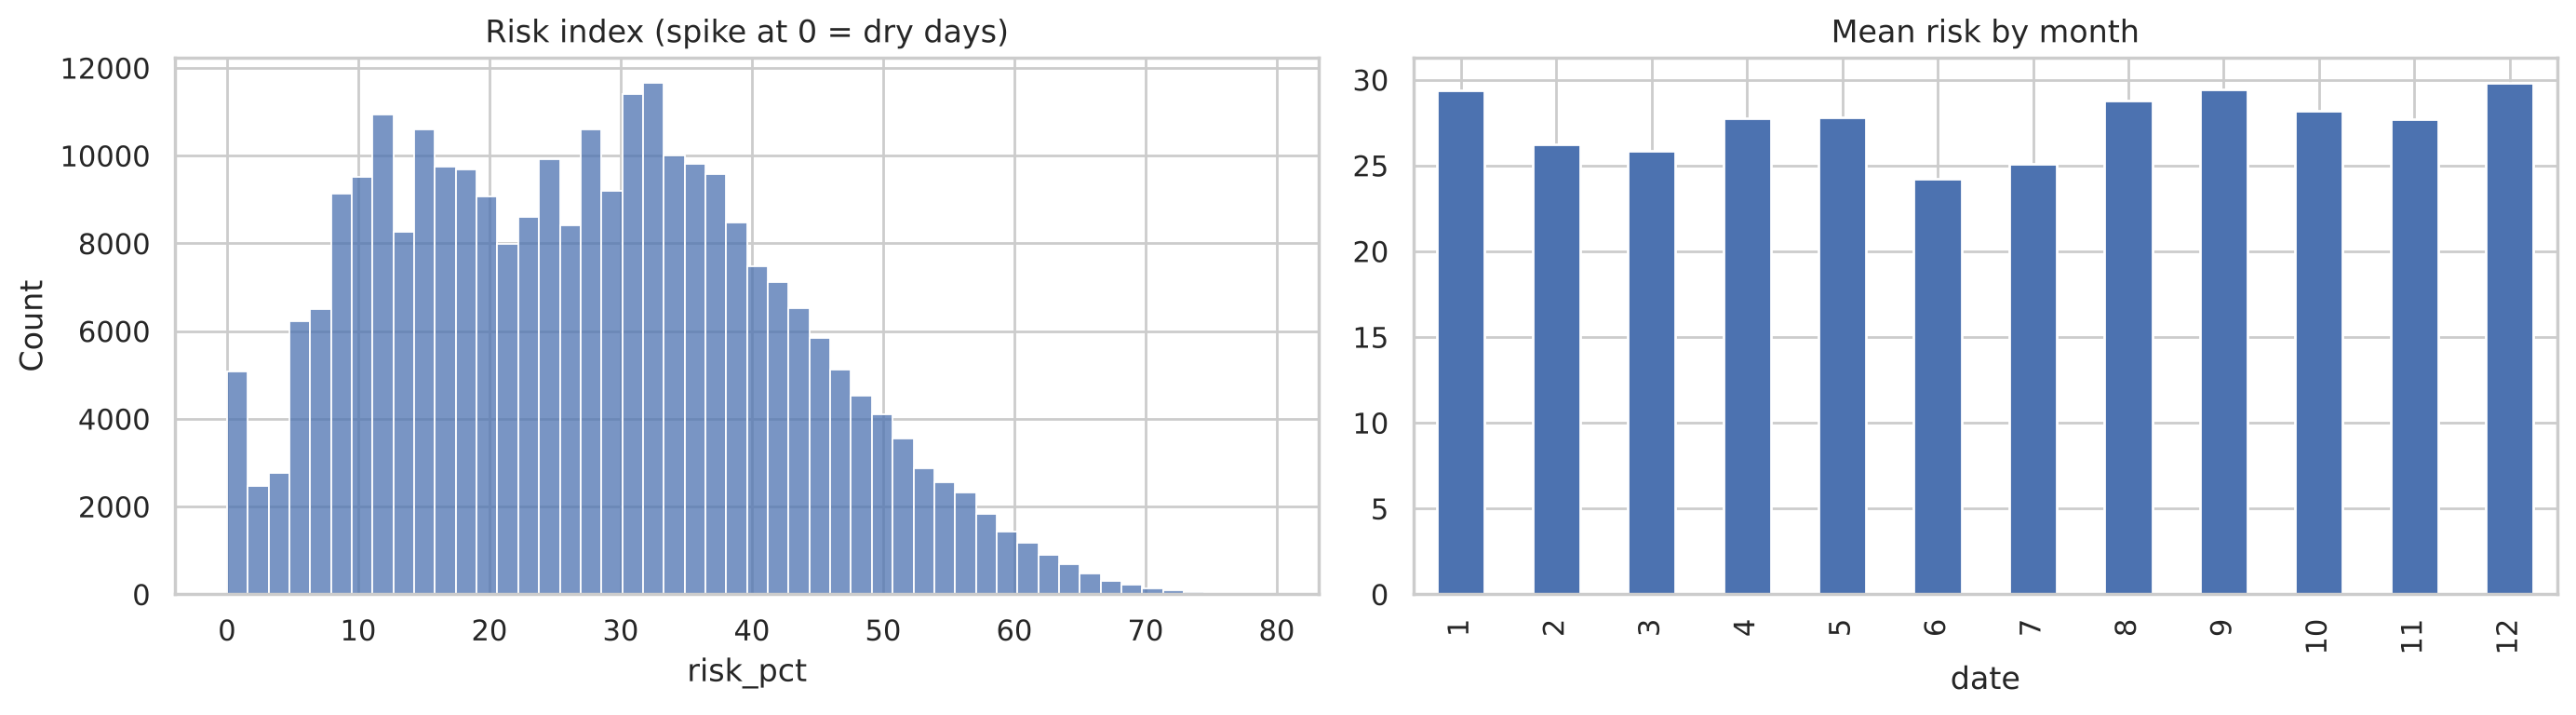

share of dry days (risk = 0): 0.008


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(raw[TARGET], bins=50, ax=ax[0]); ax[0].set_title("Risk index (spike at 0 = dry days)")
raw.groupby(raw.date.dt.month)[TARGET].mean().plot(kind="bar", ax=ax[1], title="Mean risk by month")
plt.tight_layout(); plt.show()
print("share of dry days (risk = 0):", round((raw[TARGET] == 0).mean(), 3))

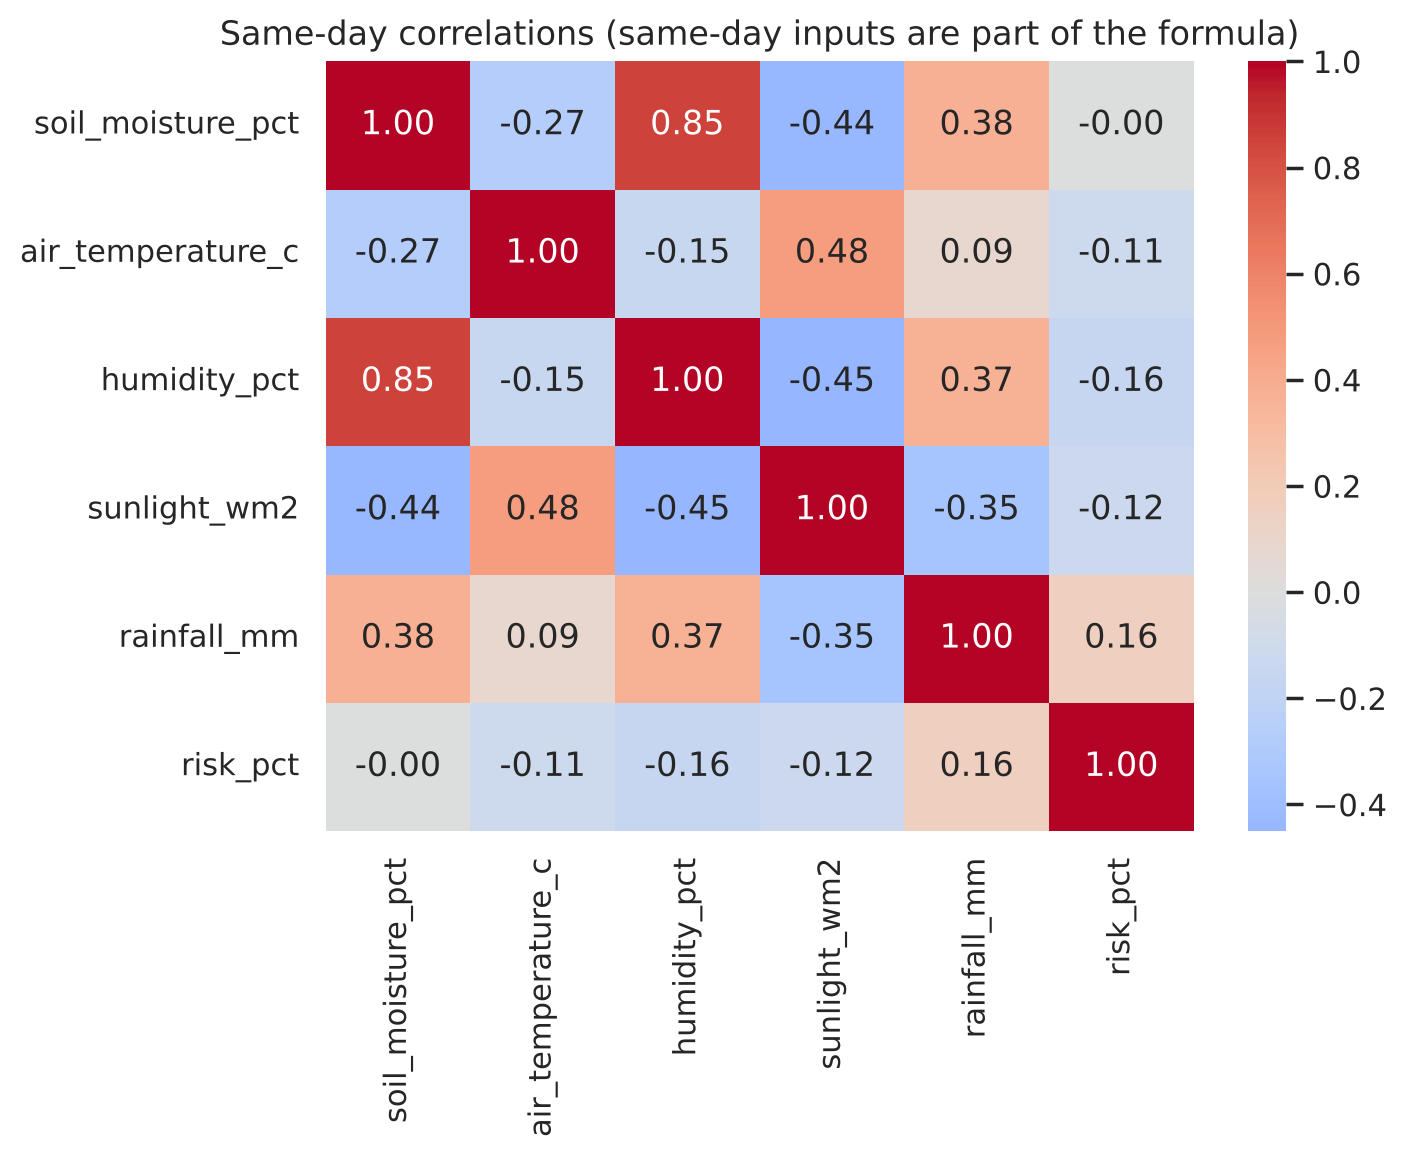

In [6]:
cols = ["soil_moisture_pct", "air_temperature_c", "humidity_pct", "sunlight_wm2", "rainfall_mm", TARGET]
plt.figure(figsize=(7, 5))
sns.heatmap(raw[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Same-day correlations (same-day inputs are part of the formula)")
plt.show()

In [7]:
print("Soil moisture and humidity correlation:", round(raw[["soil_moisture_pct", "humidity_pct"]].corr().iloc[0, 1], 3))
print("(high values mean these two carry overlapping information; watch them in the feature importance)")

Soil moisture and humidity correlation: 0.854
(high values mean these two carry overlapping information; watch them in the feature importance)


## 6. Leakage check
The same-day score says how well the formula can be reproduced. Only the previous-day score says anything about early warning.

In [8]:
same_day = DYNAMIC + STATIC + ["doy_sin", "doy_cos"]
lag_all = add_features(raw).dropna(subset=FEATURES + [TARGET])
lag_ready = lag_all                                    # used by the split and the models below
tr_s = lag_all.date.dt.year <= TRAIN_END
te_s = lag_all.date.dt.year > VAL_END
leak = {}
for name, cols in [("same-day weather + static (leaks the formula)", same_day),
                   ("previous-day features (what the model uses)", FEATURES)]:
    m = HistGradientBoostingRegressor(max_iter=300, random_state=RANDOM_STATE)
    m.fit(lag_all.loc[tr_s, cols], lag_all.loc[tr_s, TARGET])
    leak[name] = r2_score(lag_all.loc[te_s, TARGET], m.predict(lag_all.loc[te_s, cols]))
    print(f"{name}: test R2 = {leak[name]:.3f}")
metrics_log["leakage_r2"] = {k: round(float(v), 4) for k, v in leak.items()}

same-day weather + static (leaks the formula): test R2 = 0.999


previous-day features (what the model uses): test R2 = 0.882


## 7. Features
All features come from `backend.py`. Lags use the previous day only. Rows without a full 7-day rain window are dropped, which matches the API's requirement of 7 prior days.

In [9]:
print("features:", len(FEATURES))
for f in FEATURES:
    print(" -", f)
data = lag_ready.reset_index(drop=True)
print("usable rows:", len(data))

features: 17
 - lat
 - lon
 - soil_ph
 - organic_carbon
 - clay_pct
 - sand_pct
 - silt_pct
 - elevation_m
 - soil_moisture_pct_lag1
 - air_temperature_c_lag1
 - humidity_pct_lag1
 - sunlight_wm2_lag1
 - rainfall_mm_lag1
 - rain_sum3_prev
 - rain_sum7_prev
 - doy_sin
 - doy_cos
usable rows: 274680


## 8. Time-based split and baseline
Random splits leak neighbouring days into the test set, so the split is by year. The baseline predicts each point's average risk for the same day of year.

In [10]:
train = data[data.date.dt.year <= TRAIN_END]
val = data[data.date.dt.year.between(TRAIN_END + 1, VAL_END)]
test = data[data.date.dt.year > VAL_END]
trainval = data[data.date.dt.year <= VAL_END]
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,}")
X_tr, y_tr = train[FEATURES], train[TARGET]
X_va, y_va = val[FEATURES], val[TARGET]

def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}

def climatology(ref, target_df):
    ref = ref.assign(doy=ref.date.dt.dayofyear)
    m = ref.groupby(["lat", "lon", "doy"])[TARGET].mean()
    key = pd.MultiIndex.from_arrays([target_df.lat, target_df.lon, target_df.date.dt.dayofyear])
    pred = m.reindex(key).to_numpy()
    point_mean = ref.groupby(["lat", "lon"])[TARGET].mean()
    fb = pd.MultiIndex.from_arrays([target_df.lat, target_df.lon]).map(point_mean).to_numpy()
    return np.where(np.isnan(pred), fb, pred)

base_val = metrics(y_va, climatology(train, val))
print("baseline, validation:", {k: round(float(v), 3) for k, v in base_val.items()})

train 204,344 | validation 30,688 | test 39,648
baseline, validation: {'MAE': 8.16, 'RMSE': 10.662, 'R2': 0.442}


## 9. Modelling
Bagging (Random Forest, Extra Trees) averages trees trained on random samples and reduces variance. Boosting (HistGB, LightGBM, XGBoost) adds trees in sequence and reduces bias. Ridge is a linear reference.

In [11]:
models = {
    "Ridge (linear)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest (bagging)": RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                                     max_samples=0.5, bootstrap=True, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees (bagging)": ExtraTreesRegressor(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                                 max_samples=0.5, bootstrap=True, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGB (boosting)": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=31,
                                                       random_state=RANDOM_STATE),
    "LightGBM (boosting)": lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                             subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1),
    "XGBoost (boosting)": xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8,
                                           colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1),
}
rows, fitted = [], {}
for name, est in models.items():
    t0 = time.time()
    est.fit(X_tr, y_tr)
    fitted[name] = est
    mt, mv = metrics(y_tr, est.predict(X_tr)), metrics(y_va, est.predict(X_va))
    rows.append({"model": name, "train_RMSE": mt["RMSE"], "val_RMSE": mv["RMSE"],
                 "train_R2": mt["R2"], "val_R2": mv["R2"], "seconds": round(time.time() - t0, 1)})
diag = pd.DataFrame(rows)
diag["gap_%"] = 100 * (diag.val_RMSE - diag.train_RMSE) / diag.val_RMSE
display(diag.round(3))

,model,train_RMSE,val_RMSE,train_R2,val_R2,seconds,gap_%
0,Ridge (linear),13.136,12.942,0.215,0.177,0.1,-1.500
1,Random Forest (bagging),4.843,5.186,0.893,0.868,52.9,6.617
2,Extra Trees (bagging),5.097,5.280,0.882,0.863,9.7,3.478
3,HistGB (boosting),4.697,4.985,0.900,0.878,5.7,5.775
4,LightGBM (boosting),4.587,4.960,0.904,0.879,6.9,7.519
5,XGBoost (boosting),4.486,4.946,0.908,0.880,5.3,9.291


## 10. Diagnosis: overfitting and underfitting
- **Underfitting:** training R² below 0.6 (rule of thumb).
- **Overfitting:** validation RMSE more than 15% above training RMSE (rule of thumb).
- The learning curve shows whether more data would help.

In [12]:
def diagnose(r):
    if r.train_R2 < 0.6:
        return "underfitting"
    if r["gap_%"] > 15:
        return "overfitting"
    return "balanced"
diag["diagnosis"] = diag.apply(diagnose, axis=1)
display(diag[["model", "train_R2", "val_R2", "gap_%", "diagnosis"]].round(3))
metrics_log["diagnosis"] = diag[["model", "train_R2", "val_R2", "gap_%", "diagnosis"]].round(4).to_dict("records")

,model,train_R2,val_R2,gap_%,diagnosis
0,Ridge (linear),0.215,0.177,-1.500,underfitting
1,Random Forest (bagging),0.893,0.868,6.617,balanced
2,Extra Trees (bagging),0.882,0.863,3.478,balanced
3,HistGB (boosting),0.900,0.878,5.775,balanced
4,LightGBM (boosting),0.904,0.879,7.519,balanced
5,XGBoost (boosting),0.908,0.880,9.291,balanced


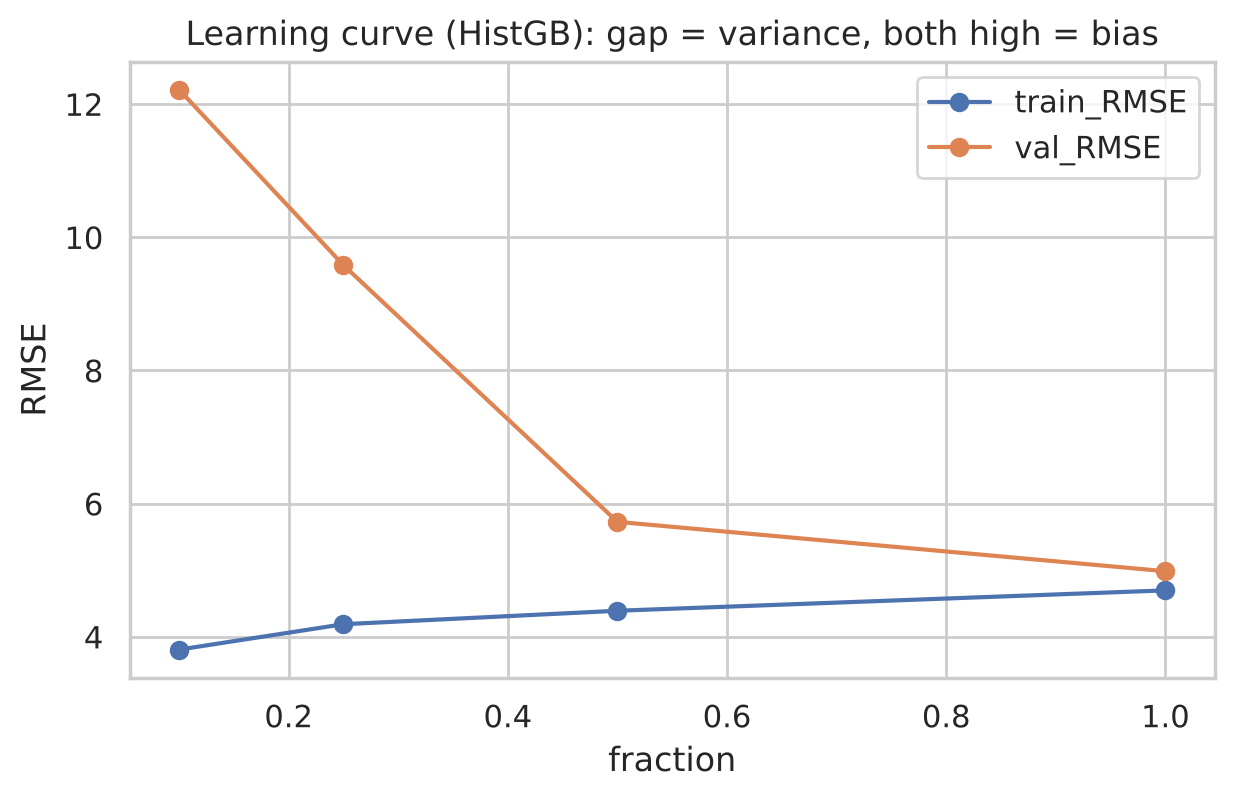

In [13]:
lc = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    n = int(len(X_tr) * frac)
    est = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=31, random_state=RANDOM_STATE)
    est.fit(X_tr.iloc[:n], y_tr.iloc[:n])
    lc.append({"fraction": frac,
               "train_RMSE": np.sqrt(mean_squared_error(y_tr.iloc[:n], est.predict(X_tr.iloc[:n]))),
               "val_RMSE": np.sqrt(mean_squared_error(y_va, est.predict(X_va)))})
pd.DataFrame(lc).plot(x="fraction", y=["train_RMSE", "val_RMSE"], marker="o", figsize=(7, 4),
                      title="Learning curve (HistGB): gap = variance, both high = bias")
plt.ylabel("RMSE"); plt.show()

## 11. Tuning
Search uses time-series cross-validation on training years only. Stronger regularisation (larger leaves, shallower trees, L2 penalty) addresses overfitting. More capacity addresses underfitting.

In [14]:
tscv = TimeSeriesSplit(n_splits=3)
spaces = {
    "HistGB": (HistGradientBoostingRegressor(random_state=RANDOM_STATE), {
        "learning_rate": [0.02, 0.05, 0.1], "max_iter": [200, 400, 800], "max_leaf_nodes": [15, 31, 63],
        "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 0.1, 1.0]}),
    "Random Forest": (RandomForestRegressor(n_estimators=60, n_jobs=-1, random_state=RANDOM_STATE), {
        "max_depth": [6, 10, 14, None], "min_samples_leaf": [10, 30, 80],
        "max_features": [0.5, 0.8, 1.0], "max_samples": [0.3, 0.5, 0.7]}),
}
tuned, tune_log = {}, {}
for name, (est, grid) in spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(est, grid, n_iter=6, cv=tscv, scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=1).fit(X_tr, y_tr)
    tuned[name] = rs.best_estimator_
    tune_log[name] = {"cv_rmse": round(float(-rs.best_score_), 4), "params": {k: str(v) for k, v in rs.best_params_.items()}}
    print(f"{name}: CV RMSE {-rs.best_score_:.3f} | {rs.best_params_} | {time.time() - t0:.0f}s")
tuned["Random Forest"].set_params(n_estimators=200).fit(X_tr, y_tr)
metrics_log["tuning"] = tune_log

HistGB: CV RMSE 6.599 | {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'max_iter': 800, 'learning_rate': 0.1, 'l2_regularization': 1.0} | 61s


Random Forest: CV RMSE 7.077 | {'min_samples_leaf': 30, 'max_samples': 0.5, 'max_features': 0.8, 'max_depth': 14} | 110s


## 12. Selection
Candidates are compared on the validation years only. The test years are not used yet.

In [15]:
ensemble = VotingRegressor([("rf", tuned["Random Forest"]), ("hgb", tuned["HistGB"]),
                            ("lgbm", fitted["LightGBM (boosting)"])]).fit(X_tr, y_tr)
candidates = {
    "Tuned Random Forest (bagging)": tuned["Random Forest"],
    "Tuned HistGB (boosting)": tuned["HistGB"],
    "LightGBM (boosting)": fitted["LightGBM (boosting)"],
    "XGBoost (boosting)": fitted["XGBoost (boosting)"],
    "Bagging + boosting ensemble": ensemble,
}
val_table = pd.DataFrame([{"model": n, **{k: round(float(v), 3) for k, v in metrics(y_va, e.predict(X_va)).items()}}
                          for n, e in candidates.items()]).sort_values("RMSE").reset_index(drop=True)
display(val_table)
best_name = val_table.iloc[0]["model"]
print("selected on validation:", best_name)
metrics_log["selected_model"] = best_name

,model,MAE,RMSE,R2
0,XGBoost (boosting),3.485,4.946,0.880
1,LightGBM (boosting),3.506,4.960,0.879
2,Bagging + boosting ensemble,3.513,4.965,0.879
3,Tuned HistGB (boosting),3.514,4.977,0.878
4,Tuned Random Forest (bagging),3.637,5.108,0.872


selected on validation: XGBoost (boosting)


## 13. Evaluation
The chosen model is refitted on 2000 to 2022 and scored once on 2023 to 2025. Two outputs are scored: the risk percentage, and the risk label (low, moderate, high) that the API returns.

In [16]:
final_model = clone(candidates[best_name]).fit(trainval[FEATURES], trainval[TARGET])
p_test = final_model.predict(test[FEATURES])
clim_test = climatology(trainval, test)
test_m = metrics(test[TARGET], p_test)
print("final model, test:", {k: round(float(v), 3) for k, v in test_m.items()})
print("climatology, test:", {k: round(float(v), 3) for k, v in metrics(test[TARGET], clim_test).items()})
wet = (test[TARGET] > 0).to_numpy()
print("wet days:", {k: round(float(v), 3) for k, v in metrics(test[TARGET][wet], p_test[wet]).items()})
print("dry days:", {k: round(float(v), 3) for k, v in metrics(test[TARGET][~wet], p_test[~wet]).items()})
metrics_log["test"] = {k: round(float(v), 4) for k, v in test_m.items()}
metrics_log["climatology_test"] = {k: round(float(v), 4) for k, v in metrics(test[TARGET], clim_test).items()}

final model, test: {'MAE': 3.463, 'RMSE': 4.941, 'R2': 0.884}
climatology, test: {'MAE': 7.926, 'RMSE': 10.466, 'R2': 0.48}
wet days: {'MAE': 3.477, 'RMSE': 4.955, 'R2': 0.881}
dry days: {'MAE': 1.752, 'RMSE': 2.696, 'R2': 0.0}


In [17]:
y_lab = np.array([risk_label(v) for v in test[TARGET]])
p_lab = np.array([risk_label(v) for v in p_test])
labels = ["low", "moderate", "high"]
acc = accuracy_score(y_lab, p_lab)
print(f"risk label accuracy on test: {acc:.3f}")
cm = pd.DataFrame(confusion_matrix(y_lab, p_lab, labels=labels), index=[f"true {l}" for l in labels],
                  columns=[f"pred {l}" for l in labels])
display(cm)
metrics_log["risk_label_accuracy"] = round(float(acc), 4)
metrics_log["risk_label_confusion"] = cm.to_dict()

risk label accuracy on test: 0.918


,pred low,pred moderate,pred high
true low,12883,1433,0
true moderate,1468,23340,60
true high,0,289,175


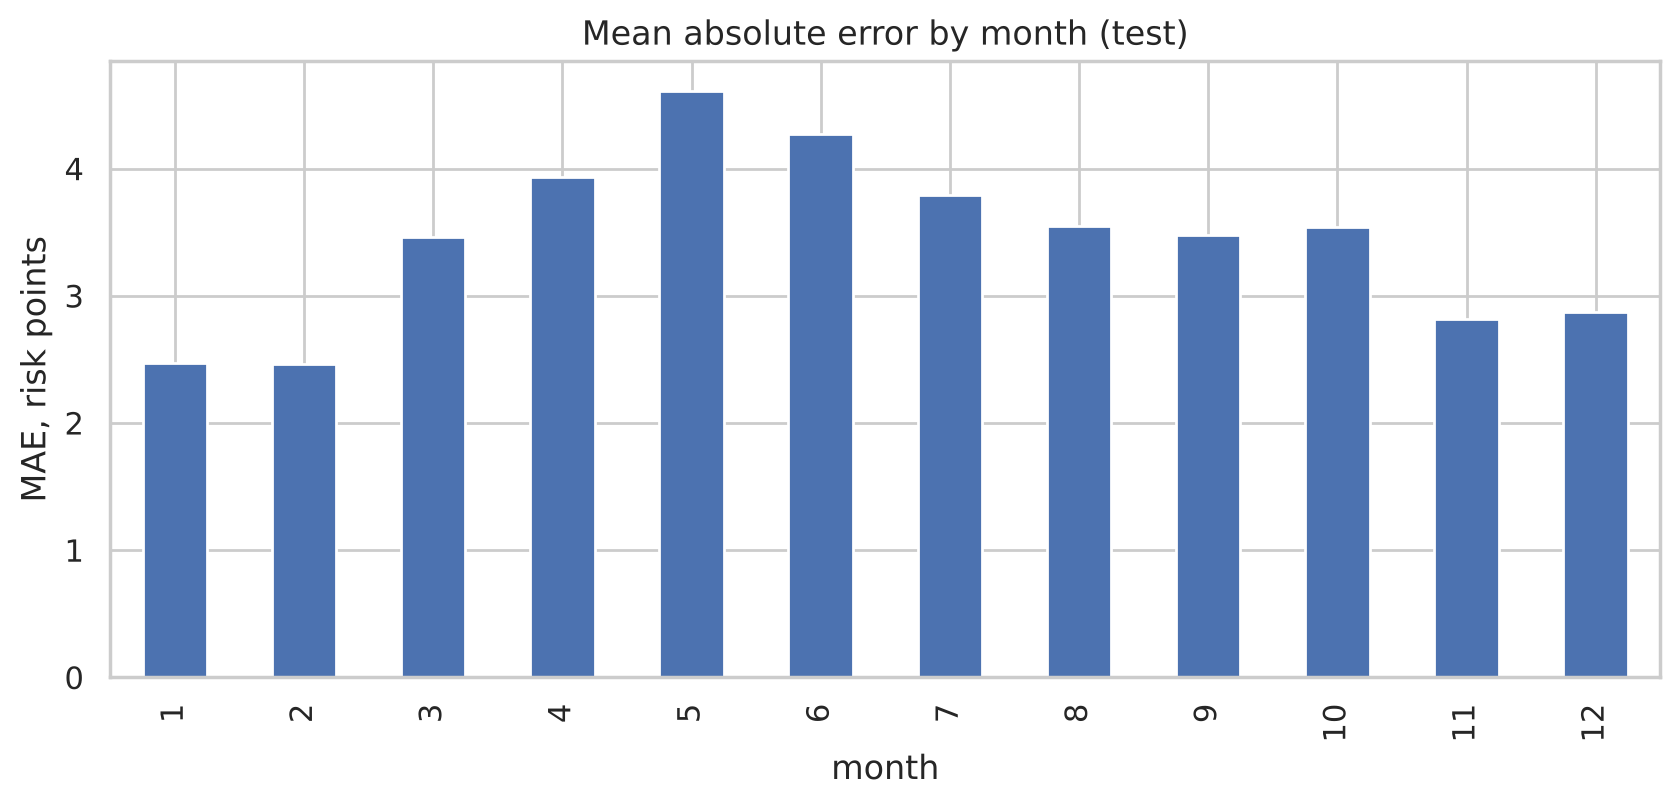

In [18]:
err = pd.DataFrame({"month": test.date.dt.month.values, "abs_err": np.abs(test[TARGET].values - p_test)})
err.groupby("month")["abs_err"].mean().plot(kind="bar", figsize=(10, 4), title="Mean absolute error by month (test)")
plt.ylabel("MAE, risk points"); plt.show()

### Unseen points
Four points are held out completely: the model is trained without them, then tested on them.

In [19]:
pts = trainval[["lat", "lon"]].drop_duplicates().sort_values(["lat", "lon"]).to_numpy()
held = pts[np.random.default_rng(RANDOM_STATE).choice(len(pts), 4, replace=False)]
held_idx = pd.MultiIndex.from_arrays([held[:, 0], held[:, 1]])
is_held = pd.MultiIndex.from_arrays([trainval.lat, trainval.lon]).isin(held_idx)
gen_model = clone(candidates[best_name]).fit(trainval[~is_held][FEATURES], trainval[~is_held][TARGET])
ht = test[pd.MultiIndex.from_arrays([test.lat, test.lon]).isin(held_idx)]
unseen = metrics(ht[TARGET], gen_model.predict(ht[FEATURES]))
print("held-out points:", [tuple(map(float, h)) for h in held])
print("unseen points, test:", {k: round(float(v), 3) for k, v in unseen.items()})
metrics_log["unseen_points"] = {k: round(float(v), 4) for k, v in unseen.items()}

held-out points: [(23.34, 85.31), (13.08, 80.27), (25.61, 85.14), (26.85, 80.95)]
unseen points, test: {'MAE': 4.772, 'RMSE': 6.171, 'R2': 0.823}


## 14. Deployment artefacts and API check
Save the model, the static soil table and the metrics. Then check that the API returns the same risk for a test day as the notebook does.

In [20]:
bundle = {"model": final_model, "features": FEATURES, "target": TARGET,
          "trained_through": VAL_END, "selected_model": best_name}
joblib.dump(bundle, MODEL_DIR / "sarva_mitra_risk_model.joblib")
static = raw.groupby(["lat", "lon"])[RECORD_STATIC].first().reset_index()
static.to_csv(MODEL_DIR / "static_features.csv", index=False)
(MODEL_DIR / "metrics.json").write_text(json.dumps(metrics_log, indent=2, default=str), encoding="utf-8")
print("saved model, static table and metrics to", MODEL_DIR)

saved model, static table and metrics to /tmp/claude-0/-home-claude/ce88828e-2e71-52c0-808c-1cf39526b7be/scratchpad/ml_build/models


In [21]:
from fastapi.testclient import TestClient
import backend
backend.MODEL_PATH = MODEL_DIR / "sarva_mitra_risk_model.joblib"
backend.STATIC_PATH = MODEL_DIR / "static_features.csv"
from backend import app

pt = raw[(raw.lat == 17.39) & (raw.lon == 78.49)].sort_values("date").reset_index(drop=True)
i = pt.index[pt.date >= "2024-07-01"][0]
def rec(r):
    return {"date": r.date.strftime("%Y-%m-%d"), "soil_moisture_pct": float(r.soil_moisture_pct),
            "air_temperature_c": float(r.air_temperature_c), "humidity_pct": float(r.humidity_pct),
            "sunlight_wm2": None if pd.isna(r.sunlight_wm2) else float(r.sunlight_wm2), "rainfall_mm": float(r.rainfall_mm)}
body = {"device_id": "dev-01", "lat": 17.39, "lon": 78.49, "target_date": pt.date[i].strftime("%Y-%m-%d"),
        "history": [rec(r) for r in pt.iloc[i-8:i-1].itertuples()],
        "current": {k: v for k, v in rec(pt.iloc[i-1]).items() if k != "date"}}
with TestClient(app) as c:
    j = c.post("/predict", json=body).json()
nb_ref = float(np.clip(final_model.predict(add_features(raw).query("lat == 17.39 and lon == 78.49 and date == @pt.date[@i]")[FEATURES])[0], 0, 100))
print("API:", j["prediction"]["risk_pct"], j["prediction"]["risk_label"], "| notebook:", round(nb_ref, 2), "| match:", j["prediction"]["risk_pct"] == round(nb_ref, 2))

API: 6.23 low | notebook: 6.23 | match: True


## 15. Monitoring and retraining (plan)
- **Input drift:** compare the sensor's daily averages with the training data each month. Sensor readings are not identical to NASA POWER or Open-Meteo values, so expect an offset at first.
- **Score drift:** when field disease records exist, track label accuracy and error by month. A rising error means retrain.
- **Retrain when:** new seasons of field data arrive, or the drift check fails for two months running.
- **Sensor check first:** before retraining on sensor data, confirm the units: rainfall in mm per day, sunlight in W/m², soil moisture in %.

**Limits:** the target is a weather-based index. These results show how well the model forecasts the index. They do not show how well it predicts crop disease. Validate against field records before presenting any accuracy as disease prediction.